# Proyecto 4 — Clasificación para Autenticación de Billetes

**Comparación experimental: SVM lineal vs Random Forest**

- Dataset: `data_banknote_authentication.txt` (UCI — Banknote Authentication)
- Clases: `0 = genuino`, `1 = falsificado`
- Semilla global: `42`

---

### Estructura del notebook (alineada con las 7 secciones del PDF)

1. **Formulación del problema** + EDA
2. **Selección de métricas** — Recall₁ como principal (contexto: aceptar falsificación es costoso)
3. **Selección de algoritmos** — SVM lineal vs Random Forest (familias distintas)
4. **Preparación** — `StandardScaler` solo donde se requiere; fit solo en train (sin fuga)
5. **Diseño experimental** — 5×2 CV anidada, semilla fija
6. **Análisis estadístico** — Shapiro-Wilk + t-test pareado + Wilcoxon (robustez)
7. **Evaluación final** en hold-out + figuras + guardado de resultados

### Entregables generados en `./resultados/`

- `01_resumen_cv.csv` — resumen de validación cruzada
- `02_mediciones_por_pliegue.csv` — **mediciones por pliegue (exigido)**
- `03_prueba_estadistica.txt` — hipótesis, W/t, p-valor, tamaño de efecto
- `04_resultados_test.csv` — métricas finales en hold-out
- `05_predicciones_test.csv` — predicciones y probabilidades
- `figuras/*.png` — figuras para el artículo y la presentación

## 0. Preparación del entorno

```bash
pip install numpy pandas matplotlib seaborn scikit-learn scipy jupyter
```

Coloca `data_banknote_authentication.txt` en la misma carpeta que este notebook.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro, ttest_rel, wilcoxon

from sklearn.model_selection import (
    train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
    GridSearchCV, cross_validate
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    fbeta_score, f1_score, recall_score, precision_score, roc_auc_score,
    balanced_accuracy_score, accuracy_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
    average_precision_score, make_scorer
)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

SEED = 42
np.random.seed(SEED)

DATA_PATH  = '../data/data_banknote_authentication.txt'
OUTPUT_DIR = 'resultados'
FIG_DIR    = os.path.join(OUTPUT_DIR, 'figuras')
os.makedirs(FIG_DIR, exist_ok=True)

COLUMNS = ['variance', 'skewness', 'curtosis', 'entropy', 'class']
print('Entorno listo. SEED =', SEED)

Entorno listo. SEED = 42


## 1. Formulación del problema

**Pregunta de investigación:** ¿Difiere el desempeño de un SVM con kernel lineal y un Random Forest en la detección de billetes falsificados (clase 1), medido con Recall₁ bajo validación cruzada 5×2 anidada y contrastado estadísticamente al nivel α = 0.05?

**Objetivo:** Desarrollar y comparar dos modelos para distinguir especímenes genuinos de falsificados, con énfasis en la detección de la clase de interés (falsificados).

**Predictores:** varianza, asimetría (*skewness*), curtosis y entropía — estadísticos extraídos de imágenes de billetes.

**Variable objetivo:** `class ∈ {0 = genuino, 1 = falsificado}`.

**Consecuencias de los errores (contexto de autenticación):**

- **Falso Negativo (predecir genuino cuando es falsificado):** pérdida económica directa; **error más costoso**.
- **Falso Positivo (predecir falsificado cuando es genuino):** revisión adicional, molestia al cliente, menor eficiencia.

Por eso priorizamos **Recall sobre la clase 1** (falsificados).

> **Nota de nomenclatura:** el PDF describe los errores en clave de negocio ("aceptar falsificación" vs "rechazar genuino"). En terminología estándar de ML con `class 1 = falsificado`:
> - Falso Negativo = aceptar una falsificación → costo alto.
> - Falso Positivo = rechazar un genuino → costo operativo.
>
> Adoptamos la terminología estándar de ML.

In [2]:
# --- Carga y verificación inicial ---
df = pd.read_csv(DATA_PATH, header=None, names=COLUMNS)
print(f'Dimensiones del dataset: {df.shape}')
print(f'\nDistribución de clases:\n{df["class"].value_counts().to_string()}')
print(f'\nProporción por clase:\n{df["class"].value_counts(normalize=True).round(4).to_string()}')
print(f'\nValores faltantes totales: {df.isnull().sum().sum()}')
print(f'\nTipos de datos:\n{df.dtypes.to_string()}')
df.describe().round(3)

Dimensiones del dataset: (1372, 5)

Distribución de clases:
class
0    762
1    610

Proporción por clase:
class
0    0.5554
1    0.4446

Valores faltantes totales: 0

Tipos de datos:
variance    float64
skewness    float64
curtosis    float64
entropy     float64
class         int64


,variance,skewness,curtosis,entropy,class
count,1372.000,1372.000,1372.000,1372.000,1372.000
mean,0.434,1.922,1.398,-1.192,0.445
std,2.843,5.869,4.310,2.101,0.497
min,-7.042,-13.773,-5.286,-8.548,0.000
25%,-1.773,-1.708,-1.575,-2.413,0.000
50%,0.496,2.320,0.617,-0.587,0.000
75%,2.821,6.815,3.179,0.395,1.000
max,6.825,12.952,17.927,2.450,1.000


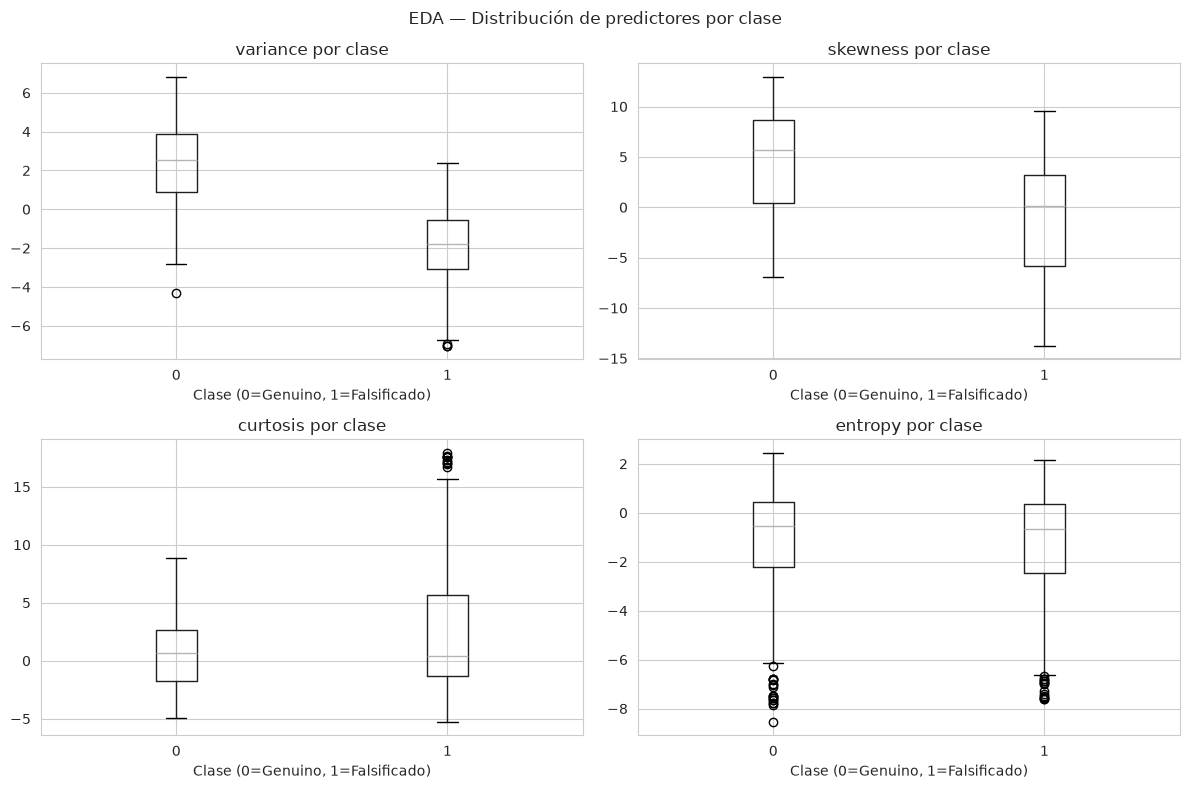

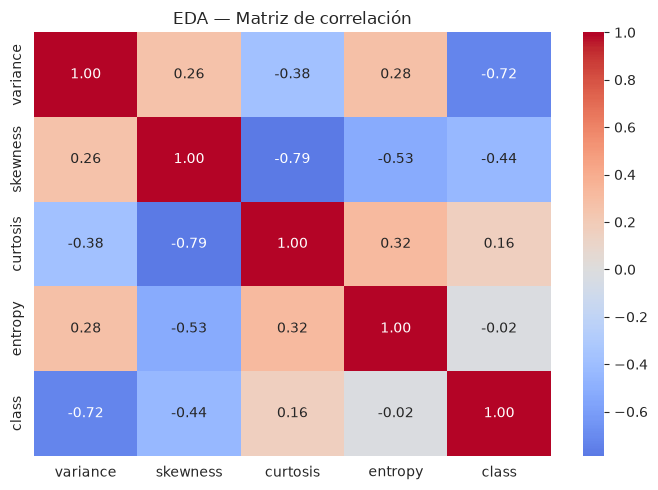

In [3]:
# --- EDA: distribuciones por clase y correlación ---
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(COLUMNS[:-1]):
    ax = axes[i // 2, i % 2]
    df.boxplot(column=col, by='class', ax=ax)
    ax.set_title(f'{col} por clase')
    ax.set_xlabel('Clase (0=Genuino, 1=Falsificado)')
plt.suptitle('EDA — Distribución de predictores por clase')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '01_eda_boxplots.png'), dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('EDA — Matriz de correlación')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '02_eda_correlacion.png'), dpi=150, bbox_inches='tight')
plt.show()

## 2. Selección de métricas

**Métrica principal:** `Recall₁ = TP / (TP + FN)` sobre la clase 1 (falsificado).

**Justificación:** cada FN implica aceptar una falsificación (pérdida económica directa). Por eso priorizamos maximizar la detección de falsificaciones.

**Métricas complementarias:**

- `Precision₁ = TP / (TP + FP)` — coste de las revisiones innecesarias.
- `F1₁` y `F2₁` — equilibrio entre Recall y Precision (`F2` pondera más el Recall).
- `Specificity = TN / (TN + FP)` — capacidad de no rechazar genuinos.
- `ROC-AUC` — rendimiento global al variar el umbral.
- `Balanced Accuracy` — robusto ante desbalance moderado.

> Se evalúan todas durante el CV; la prueba estadística principal se hace sobre `Recall₁`.

In [4]:
SCORING = {
    'recall_class1'   : make_scorer(recall_score,    pos_label=1),   # métrica principal
    'precision_class1': make_scorer(precision_score, pos_label=1),
    'specificity'     : make_scorer(recall_score,    pos_label=0),   # = recall de clase 0
    'f1_class1'       : make_scorer(f1_score,        pos_label=1),
    'f2_class1'       : make_scorer(fbeta_score, beta=2, pos_label=1),
    'roc_auc'         : 'roc_auc',
    'balanced_acc'    : 'balanced_accuracy',
    'accuracy'        : 'accuracy',
}
MAIN_METRIC = 'test_recall_class1'
print('Métrica principal:', MAIN_METRIC)

Métrica principal: test_recall_class1


## 3. Selección de algoritmos

**A) SVM con kernel lineal** — modelo discriminativo basado en márgenes máximos. Aprende un hiperplano óptimo maximizando el margen entre clases. Es sensible a escala → requiere `StandardScaler`. Su regularización se controla con `C`.

**B) Random Forest** — ensemble de árboles de decisión entrenados con bagging. No lineal, invariante a escala y robusto frente a outliers. Se ajusta con `n_estimators`, `max_depth` y `min_samples_leaf`.

**¿Por qué estos dos y no otros?**

| Criterio | Argumento |
|---|---|
| **Familias distintas** | SVM lineal = discriminativo/margen; RF = ensemble no lineal por particiones. |
| **Adecuación al problema** | 4 predictores continuos, ~1100 ejemplos en train, clases moderadamente desbalanceadas. |
| **Descarte explícito** | KNN (lazy, baseline débil), Naive Bayes (viola independencia: predictores correlacionados), Perceptrón Simple (lineal sin probabilidades), MLP (sobredimensionado para n≈1372), k-means/enjambres (no son clasificadores). |

In [5]:
# A) SVM lineal (con StandardScaler dentro del pipeline → sin fuga)
svm_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    SVC(kernel='linear', probability=True, random_state=SEED))
])

# B) Random Forest (sin escalado: invariante a escala)
rf_pipe = Pipeline([
    ('clf', RandomForestClassifier(random_state=SEED, n_jobs=-1))
])

param_grid_svm = {'clf__C': [0.01, 0.1, 1, 10, 100]}

param_grid_rf = {
    'clf__n_estimators'    : [200, 500],
    'clf__max_depth'       : [None, 10, 20],
    'clf__min_samples_leaf': [1, 2, 4],
}
print('Pipelines y grids definidos.')

Pipelines y grids definidos.


## 4. Preparación y control de fuga

- **SVM lineal** requiere estandarización: los predictores tienen escalas muy diferentes (varianza hasta ~6, curtosis hasta ~17).
- **Random Forest** es invariante a escala.
- **Sin fuga de información:** todo el preprocesamiento vive **dentro** del `Pipeline`, que se ajusta en cada fold de entrenamiento y solo transforma el fold de validación. El `GridSearchCV` interno también está encerrado en el pipeline → no ve validación externa.

Verificación explícita de fuga:

In [6]:
# --- Split train/test estratificado ---
X = df.drop('class', axis=1).values
y = df['class'].values.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print(f'Clases train: {np.bincount(y_train)}')
print(f'Clases test : {np.bincount(y_test)}')
print(f'\n[OK] El escalado y el tuning están DENTRO del Pipeline.')
print('[OK] El test set NO se usa durante CV ni tuning.')

Train: (1097, 4) | Test: (275, 4)
Clases train: [609 488]
Clases test : [153 122]

[OK] El escalado y el tuning están DENTRO del Pipeline.
[OK] El test set NO se usa durante CV ni tuning.


## 5. Diseño experimental — 5×2 CV anidada

- **Exterior:** `RepeatedStratifiedKFold(n_splits=5, n_repeats=2)` → **10 pliegues pareados** (diseño 5×2). Cada pliegue entrena ambos algoritmos sobre el mismo subconjunto de entrenamiento.
- **Interior:** `StratifiedKFold(n_splits=3)` para `GridSearchCV`.
- **Semilla:** `SEED = 42` en todo.
- **Sin fuga:** el tuning se hace solo con el train interno del pliegue externo.

Se registran las 10 mediciones pareadas para ambos algoritmos, que es lo que la prueba estadística consume.

In [7]:
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

svm_nested = GridSearchCV(
    estimator=svm_pipe, param_grid=param_grid_svm,
    cv=inner_cv, scoring='f1', n_jobs=-1, refit=True
)
rf_nested = GridSearchCV(
    estimator=rf_pipe, param_grid=param_grid_rf,
    cv=inner_cv, scoring='f1', n_jobs=-1, refit=True
)

print('>>> Evaluando SVM lineal (nested CV)...')
svm_cv = cross_validate(svm_nested, X_train, y_train,
                        cv=outer_cv, scoring=SCORING, n_jobs=1)

print('>>> Evaluando Random Forest (nested CV)...')
rf_cv = cross_validate(rf_nested, X_train, y_train,
                       cv=outer_cv, scoring=SCORING, n_jobs=1)

print('\nListo. Pliegues evaluados:', len(svm_cv['test_recall_class1']))

>>> Evaluando SVM lineal (nested CV)...
>>> Evaluando Random Forest (nested CV)...

Listo. Pliegues evaluados: 10


In [8]:
# --- Resumen CV (media, std, min, max por algoritmo y métrica) ---
def summarize_cv(name, cv_res):
    rows = []
    for metric in [m for m in cv_res if m.startswith('test_')]:
        vals = cv_res[metric]
        rows.append({
            'algoritmo': name,
            'metrica'  : metric.replace('test_', ''),
            'media'    : float(np.mean(vals)),
            'std'      : float(np.std(vals, ddof=1)),
            'min'      : float(np.min(vals)),
            'max'      : float(np.max(vals)),
        })
    return pd.DataFrame(rows)

cv_summary = pd.concat(
    [summarize_cv('SVM_lineal', svm_cv), summarize_cv('RandomForest', rf_cv)],
    ignore_index=True
)
cv_summary.to_csv(os.path.join(OUTPUT_DIR, '01_resumen_cv.csv'), index=False)

print('--- Media por métrica en CV (10 folds) ---')
cv_summary.pivot(index='metrica', columns='algoritmo', values='media').round(4)

--- Media por métrica en CV (10 folds) ---


algoritmo,RandomForest,SVM_lineal
metrica,,
accuracy,0.9941,0.9923
balanced_acc,0.9947,0.9925
f1_class1,0.9934,0.9913
f2_class1,0.9974,0.9934
precision_class1,0.9870,0.9879
recall_class1,1.0000,0.9949
roc_auc,0.9998,0.9996
specificity,0.9893,0.9902


In [9]:
# --- Mediciones por pliegue (entregable requerido) ---
cv_per_fold = pd.DataFrame({
    'fold'        : np.arange(1, len(svm_cv['test_recall_class1']) + 1),
    'SVM_recall'  : svm_cv['test_recall_class1'],
    'SVM_f1'      : svm_cv['test_f1_class1'],
    'SVM_f2'      : svm_cv['test_f2_class1'],
    'SVM_prec'    : svm_cv['test_precision_class1'],
    'SVM_auc'     : svm_cv['test_roc_auc'],
    'RF_recall'   : rf_cv['test_recall_class1'],
    'RF_f1'       : rf_cv['test_f1_class1'],
    'RF_f2'       : rf_cv['test_f2_class1'],
    'RF_prec'     : rf_cv['test_precision_class1'],
    'RF_auc'      : rf_cv['test_roc_auc'],
})
cv_per_fold['diff_recall'] = cv_per_fold['SVM_recall'] - cv_per_fold['RF_recall']
cv_per_fold.to_csv(os.path.join(OUTPUT_DIR, '02_mediciones_por_pliegue.csv'), index=False)
print('Guardado: 02_mediciones_por_pliegue.csv')
cv_per_fold.round(4)

Guardado: 02_mediciones_por_pliegue.csv


,fold,SVM_recall,SVM_f1,SVM_f2,SVM_prec,SVM_auc,RF_recall,RF_f1,RF_f2,RF_prec,RF_auc,diff_recall
0,1,1.0000,0.9849,0.9939,0.9703,0.9991,1.0,0.9899,0.9959,0.9800,0.9999,0.0000
1,2,0.9898,0.9898,0.9898,0.9898,0.9997,1.0,1.0000,1.0000,1.0000,1.0000,-0.0102
2,3,1.0000,0.9949,0.9980,0.9899,0.9997,1.0,0.9899,0.9959,0.9800,1.0000,0.0000
3,4,0.9897,0.9897,0.9897,0.9897,0.9995,1.0,1.0000,1.0000,1.0000,1.0000,-0.0103
4,5,1.0000,1.0000,1.0000,1.0000,1.0000,1.0,0.9848,0.9939,0.9700,0.9995,0.0000
5,6,1.0000,0.9949,0.9980,0.9899,0.9999,1.0,0.9949,0.9980,0.9899,1.0000,0.0000
6,7,1.0000,0.9949,0.9980,0.9899,0.9997,1.0,0.9949,0.9980,0.9899,1.0000,0.0000
7,8,0.9694,0.9845,0.9754,1.0000,0.9996,1.0,0.9849,0.9939,0.9703,0.9990,-0.0306
8,9,1.0000,0.9848,0.9939,0.9700,0.9989,1.0,0.9949,0.9979,0.9898,1.0000,0.0000
9,10,1.0000,0.9949,0.9979,0.9898,0.9996,1.0,1.0000,1.0000,1.0000,1.0000,0.0000


## 6. Análisis estadístico

**Hipótesis (sobre `Recall₁`):**

- **H₀:** la mediana de las diferencias pareadas `Recall_SVM − Recall_RF` es igual a 0.
- **H₁:** la mediana de las diferencias pareadas es distinta de 0.
- **α = 0.05**

**Procedimiento:**

1. **Shapiro-Wilk** sobre las diferencias pareadas → ¿se puede asumir normalidad?
2. **Paired t-test** (prueba principal según sugerencias del proyecto) → devuelve `t` y `p`.
3. **Wilcoxon signed-rank** (robustez) → confirma si la conclusión se mantiene sin supuesto de normalidad.
4. **Tamaño de efecto** (Cohen's d pareado) → distingue significancia estadística de relevancia práctica.

> El diseño 5×2 CV es **pareado** (mismos pliegues para ambos algoritmos), condición necesaria para `ttest_rel` y `wilcoxon`.

In [10]:
recall_svm = svm_cv['test_recall_class1']
recall_rf  = rf_cv['test_recall_class1']
diffs = recall_svm - recall_rf

print('=' * 70)
print(' ANÁLISIS ESTADÍSTICO — Recall₁ (clase falsificada)')
print('=' * 70)
print(f'N pares           : {len(diffs)}')
print(f'SVM Rec₁ media±std: {recall_svm.mean():.4f} ± {recall_svm.std(ddof=1):.4f}')
print(f'RF  Rec₁ media±std: {recall_rf.mean():.4f} ± {recall_rf.std(ddof=1):.4f}')
print(f'Diferencia media  : {diffs.mean():+.4f}')
print(f'Mediana diferencia: {np.median(diffs):+.4f}')

# 1) Shapiro-Wilk (¿se puede asumir normalidad?)
sh_stat, sh_p = shapiro(diffs)
print(f'\nShapiro-Wilk: W={sh_stat:.4f}, p={sh_p:.4f}')
if sh_p > 0.05:
    print('  -> No se rechaza normalidad (p>0.05). t-test pareado es apropiado.')
else:
    print('  -> Se rechaza normalidad (p<0.05). Wilcoxon como principal + t-test como referencia.')

# 2) Paired t-test
t_stat, t_p = ttest_rel(recall_svm, recall_rf)
d_cohen = diffs.mean() / diffs.std(ddof=1)
print(f'\nPaired t-test: t={t_stat:.4f}, p={t_p:.6f}')
print(f"Cohen's d   : {d_cohen:.4f}")

# 3) Wilcoxon signed-rank (robustez)
try:
    w_stat, w_p = wilcoxon(recall_svm, recall_rf, zero_method='wilcox')
    print(f'Wilcoxon    : W={w_stat:.4f}, p={w_p:.6f}')
except Exception as e:
    print(f'Wilcoxon no aplicable: {e}')

 ANÁLISIS ESTADÍSTICO — Recall₁ (clase falsificada)
N pares           : 10
SVM Rec₁ media±std: 0.9949 ± 0.0099
RF  Rec₁ media±std: 1.0000 ± 0.0000
Diferencia media  : -0.0051
Mediana diferencia: +0.0000

Shapiro-Wilk: W=0.6043, p=0.0001
  -> Se rechaza normalidad (p<0.05). Wilcoxon como principal + t-test como referencia.

Paired t-test: t=-1.6293, p=0.137681
Cohen's d   : -0.5152
Wilcoxon    : W=0.0000, p=0.250000


In [11]:
# --- Reporte formal de la prueba ---
alpha = 0.05
print('=' * 70)
print(f' Decisión con alpha = {alpha}')
print('=' * 70)
if t_p < alpha:
    winner = 'SVM_lineal' if diffs.mean() > 0 else 'RandomForest'
    print(f'Se RECHAZA H0. Diferencia estadísticamente significativa.')
    print(f'Mejor Recall₁ medio: {winner}.')
else:
    print('NO se rechaza H0. Sin evidencia de diferencia significativa.')
    print('(Recuerda: no significativo no implica equivalencia.)')

# Guardar reporte
with open(os.path.join(OUTPUT_DIR, '03_prueba_estadistica.txt'), 'w') as fh:
    fh.write('PRUEBA DE HIPÓTESIS — Recall₁ (clase 1, falsificado)\n')
    fh.write('=' * 60 + '\n')
    fh.write(f'N pares            : {len(diffs)}\n')
    fh.write(f'SVM Rec₁ media±std : {recall_svm.mean():.4f} ± {recall_svm.std(ddof=1):.4f}\n')
    fh.write(f'RF  Rec₁ media±std : {recall_rf.mean():.4f} ± {recall_rf.std(ddof=1):.4f}\n')
    fh.write(f'Diferencia media   : {diffs.mean():+.4f}\n')
    fh.write(f'Mediana diferencia : {np.median(diffs):+.4f}\n\n')
    fh.write('H0: mediana de las diferencias pareadas (SVM - RF) = 0\n')
    fh.write('H1: mediana de las diferencias pareadas (SVM - RF) ≠ 0\n')
    fh.write(f'alpha = {alpha}\n\n')
    fh.write(f'Shapiro-Wilk : W={sh_stat:.4f}, p={sh_p:.4f}\n')
    fh.write(f'Paired t-test: t={t_stat:.4f}, p={t_p:.6f}\n')
    fh.write(f"Cohen's d    : {d_cohen:.4f}\n")
    try:
        fh.write(f'Wilcoxon     : W={w_stat:.4f}, p={w_p:.6f}\n')
    except NameError:
        fh.write('Wilcoxon     : no aplicable\n')
print('\nReporte guardado en 03_prueba_estadistica.txt')

 Decisión con alpha = 0.05
NO se rechaza H0. Sin evidencia de diferencia significativa.
(Recuerda: no significativo no implica equivalencia.)

Reporte guardado en 03_prueba_estadistica.txt


## 7. Evaluación final en hold-out (20%) + figuras

Refit de los mejores modelos (hiperparámetros ya elegidos por GridSearchCV) sobre **todo el train**, y evaluación sobre el test nunca usado antes.

In [12]:
svm_nested.fit(X_train, y_train)
rf_nested.fit(X_train, y_train)

svm_best = svm_nested.best_estimator_
rf_best  = rf_nested.best_estimator_

print('Mejores hiperparámetros SVM:', svm_nested.best_params_)
print('Mejores hiperparámetros RF :', rf_nested.best_params_)

def evaluate_on_test(name, model, X_te, y_te):
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]
    return {
        'algoritmo'       : name,
        'recall_class1'   : recall_score(y_te, y_pred, pos_label=1),
        'f2_class1'       : fbeta_score(y_te, y_pred, beta=2, pos_label=1),
        'f1_class1'       : f1_score(y_te, y_pred, pos_label=1),
        'precision_class1': precision_score(y_te, y_pred, pos_label=1),
        'specificity'     : recall_score(y_te, y_pred, pos_label=0),
        'roc_auc'         : roc_auc_score(y_te, y_proba),
        'avg_precision'   : average_precision_score(y_te, y_proba),
        'balanced_acc'    : balanced_accuracy_score(y_te, y_pred),
        'accuracy'        : accuracy_score(y_te, y_pred),
        'y_pred'          : y_pred,
        'y_proba'         : y_proba,
    }

res_svm = evaluate_on_test('SVM_lineal',   svm_best, X_test, y_test)
res_rf  = evaluate_on_test('RandomForest', rf_best,  X_test, y_test)

test_table = pd.DataFrame([
    {k: v for k, v in res_svm.items() if k not in ('y_pred', 'y_proba')},
    {k: v for k, v in res_rf .items() if k not in ('y_pred', 'y_proba')},
])
test_table.to_csv(os.path.join(OUTPUT_DIR, '04_resultados_test.csv'), index=False)
test_table.round(4)

Mejores hiperparámetros SVM: {'clf__C': 10}
Mejores hiperparámetros RF : {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 500}


,algoritmo,recall_class1,f2_class1,f1_class1,precision_class1,specificity,roc_auc,avg_precision,balanced_acc,accuracy
0,SVM_lineal,1.0,0.9935,0.9839,0.9683,0.9739,1.0,1.0,0.9869,0.9855
1,RandomForest,1.0,0.9984,0.9959,0.9919,0.9935,1.0,1.0,0.9967,0.9964


In [13]:
for name, res in [('SVM_lineal', res_svm), ('RandomForest', res_rf)]:
    print(f'\nClassification report — {name}')
    print(classification_report(
        y_test, res['y_pred'],
        target_names=['Genuino(0)', 'Falsificado(1)'],
        digits=4
    ))


Classification report — SVM_lineal
                precision    recall  f1-score   support

    Genuino(0)     1.0000    0.9739    0.9868       153
Falsificado(1)     0.9683    1.0000    0.9839       122

      accuracy                         0.9855       275
     macro avg     0.9841    0.9869    0.9853       275
  weighted avg     0.9859    0.9855    0.9855       275


Classification report — RandomForest
                precision    recall  f1-score   support

    Genuino(0)     1.0000    0.9935    0.9967       153
Falsificado(1)     0.9919    1.0000    0.9959       122

      accuracy                         0.9964       275
     macro avg     0.9959    0.9967    0.9963       275
  weighted avg     0.9964    0.9964    0.9964       275



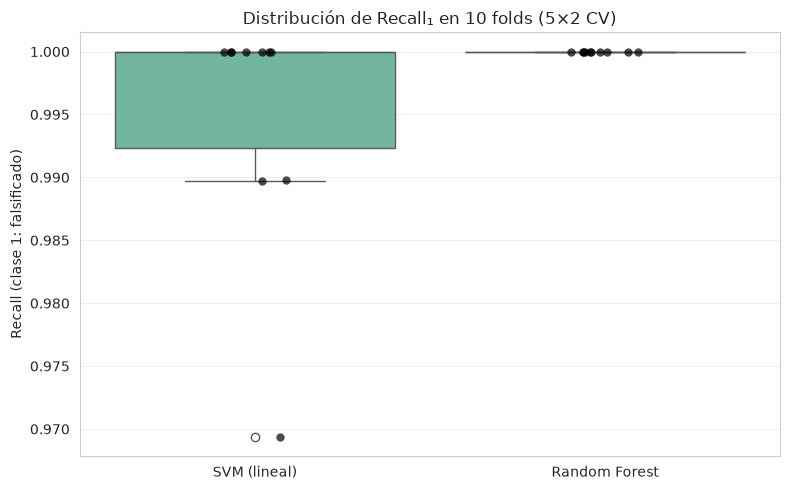

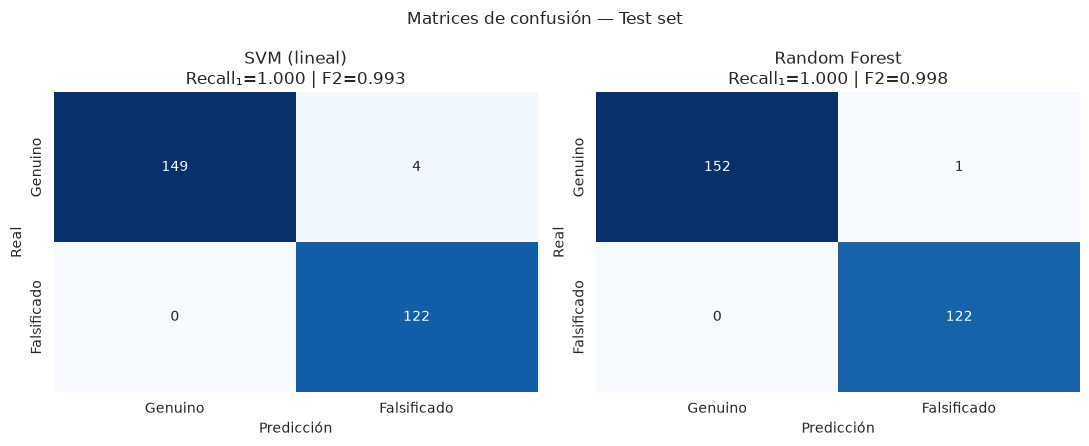

In [14]:
# --- Figura 1: boxplot CV (Recall₁) ---
plt.figure(figsize=(8, 5))
cv_df = pd.DataFrame({'SVM (lineal)': recall_svm, 'Random Forest': recall_rf})
sns.boxplot(data=cv_df, palette='Set2')
sns.stripplot(data=cv_df, color='black', size=6, alpha=0.7)
plt.ylabel('Recall (clase 1: falsificado)')
plt.title('Distribución de Recall₁ en 10 folds (5×2 CV)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '03_boxplot_cv_recall.png'), dpi=150, bbox_inches='tight')
plt.show()

# --- Figura 2: matrices de confusión ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, res) in zip(axes, [('SVM (lineal)', res_svm),
                                  ('Random Forest', res_rf)]):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Genuino', 'Falsificado'],
                yticklabels=['Genuino', 'Falsificado'])
    ax.set_title(f'{name}\nRecall₁={res["recall_class1"]:.3f} | F2={res["f2_class1"]:.3f}')
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')
plt.suptitle('Matrices de confusión — Test set')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '04_confusion_matrices.png'), dpi=150, bbox_inches='tight')
plt.show()

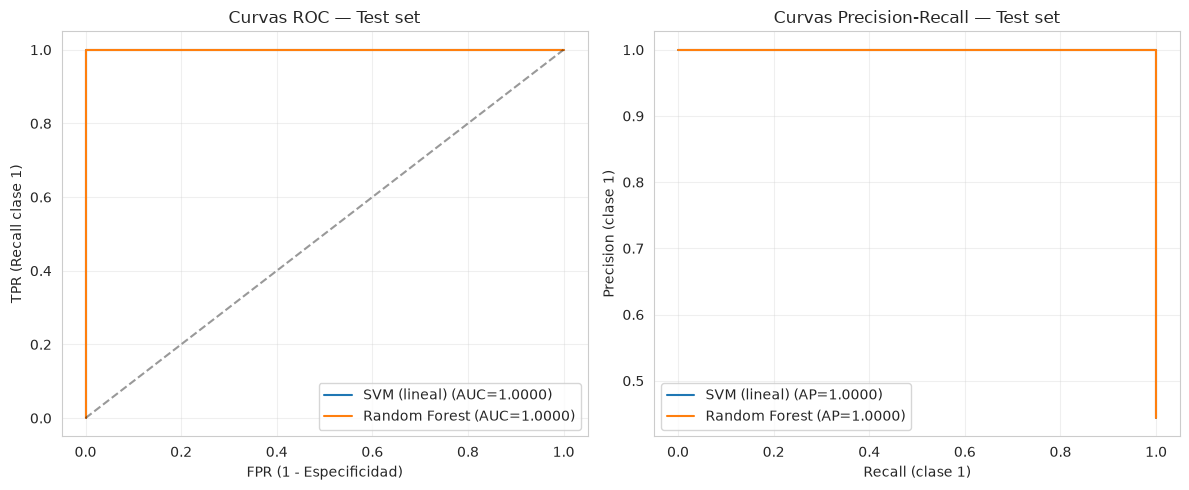

In [15]:
# --- Figura 3: curvas ROC y Precision-Recall ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, res in [('SVM (lineal)', res_svm), ('Random Forest', res_rf)]:
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={res['roc_auc']:.4f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set_xlabel('FPR (1 - Especificidad)')
axes[0].set_ylabel('TPR (Recall clase 1)')
axes[0].set_title('Curvas ROC — Test set')
axes[0].legend()
axes[0].grid(alpha=0.3)

for name, res in [('SVM (lineal)', res_svm), ('Random Forest', res_rf)]:
    prec, rec, _ = precision_recall_curve(y_test, res['y_proba'])
    axes[1].plot(rec, prec, label=f"{name} (AP={res['avg_precision']:.4f})")
axes[1].set_xlabel('Recall (clase 1)')
axes[1].set_ylabel('Precision (clase 1)')
axes[1].set_title('Curvas Precision-Recall — Test set')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '05_roc_pr_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

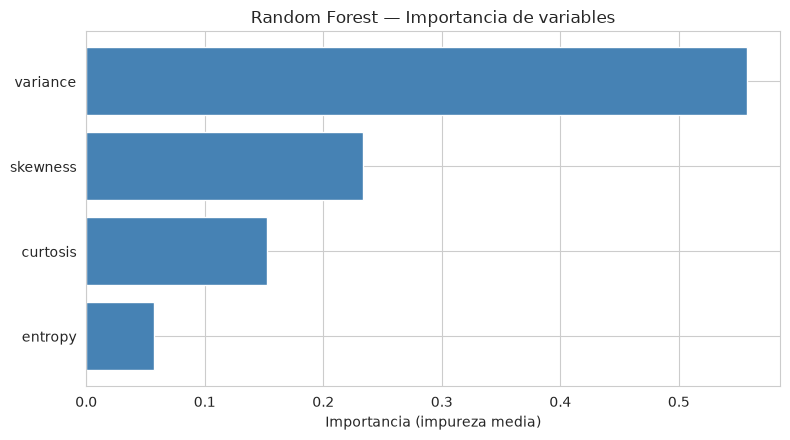

Predicciones guardadas en 05_predicciones_test.csv


In [16]:
# --- Figura 4: importancia de variables (RF) ---
rf_clf = rf_best.named_steps['clf']
imp_df = pd.DataFrame({
    'feature'   : COLUMNS[:-1],
    'importance': rf_clf.feature_importances_
}).sort_values('importance', ascending=True)

plt.figure(figsize=(8, 4.5))
plt.barh(imp_df['feature'], imp_df['importance'], color='steelblue')
plt.xlabel('Importancia (impureza media)')
plt.title('Random Forest — Importancia de variables')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '06_rf_importance.png'), dpi=150, bbox_inches='tight')
plt.show()

# --- Guardar predicciones completas del test ---
pd.DataFrame({
    'y_true'   : y_test,
    'svm_pred' : res_svm['y_pred'],
    'svm_proba': res_svm['y_proba'],
    'rf_pred'  : res_rf['y_pred'],
    'rf_proba' : res_rf['y_proba'],
}).to_csv(os.path.join(OUTPUT_DIR, '05_predicciones_test.csv'), index=False)
print('Predicciones guardadas en 05_predicciones_test.csv')

## 8. Resumen final para el artículo

El bloque de código siguiente sintetiza los resultados clave. Cópialo tal cual a la sección de **Resultados** del artículo LNCS y complementa con:

| Sección del paper | Fuente en este notebook |
|---|---|
| Introducción / pregunta | Celda 4 (markdown) |
| Marco teórico | Celda 9 (markdown, justificación de algoritmos) |
| Metodología | Celdas 5–13 |
| Resultados (CV) | `01_resumen_cv.csv`, `02_mediciones_por_pliegue.csv` |
| Resultados (test) | `04_resultados_test.csv` |
| Análisis estadístico | `03_prueba_estadistica.txt` |
| Figuras | `figuras/*.png` |
| Discusión | Celda final (plantilla) |

In [17]:
print('=' * 78)
print(' RESUMEN FINAL')
print('=' * 78)
print(f'\n[CV 5×2] Recall₁:')
print(f'  SVM lineal   : {recall_svm.mean():.4f} ± {recall_svm.std(ddof=1):.4f}')
print(f'  Random Forest: {recall_rf.mean():.4f} ± {recall_rf.std(ddof=1):.4f}')
print(f'\n[Prueba] Paired t-test: t={t_stat:.4f}, p={t_p:.4f} '
      f"({'significativo' if t_p<0.05 else 'no significativo'} a α=0.05)")
print(f"[Efecto] Cohen's d = {d_cohen:.4f}")
print(f'\n[Test hold-out]')
for name, res in [('SVM_lineal', res_svm), ('RandomForest', res_rf)]:
    print(f'  {name:14s} | Rec₁={res["recall_class1"]:.4f} | '
          f'Prec₁={res["precision_class1"]:.4f} | '
          f'Spec={res["specificity"]:.4f} | '
          f'ROC-AUC={res["roc_auc"]:.4f}')
print('\n[Discusión sugerida]')
print('  1) ¿Qué algoritmo maximiza Recall₁ en CV y en test?')
print('  2) ¿La diferencia es estadísticamente significativa (t-test)?')
print('  3) ¿Cuántos FN evita el mejor modelo en el test set?')
print('  4) Trade-off Recall vs Precision: analizar umbral o class_weight')
print('  5) Limitaciones: SVM lineal puede subajustar si la frontera real es no lineal;')
print('     considerar SVM-RBF o MLP como extensión natural.')
print('  6) Extensiones: ajustar umbral por costos, PSO para tuning, 5×2cv paired t-test.')
print('=' * 78)

 RESUMEN FINAL

[CV 5×2] Recall₁:
  SVM lineal   : 0.9949 ± 0.0099
  Random Forest: 1.0000 ± 0.0000

[Prueba] Paired t-test: t=-1.6293, p=0.1377 (no significativo a α=0.05)
[Efecto] Cohen's d = -0.5152

[Test hold-out]
  SVM_lineal     | Rec₁=1.0000 | Prec₁=0.9683 | Spec=0.9739 | ROC-AUC=1.0000
  RandomForest   | Rec₁=1.0000 | Prec₁=0.9919 | Spec=0.9935 | ROC-AUC=1.0000

[Discusión sugerida]
  1) ¿Qué algoritmo maximiza Recall₁ en CV y en test?
  2) ¿La diferencia es estadísticamente significativa (t-test)?
  3) ¿Cuántos FN evita el mejor modelo en el test set?
  4) Trade-off Recall vs Precision: analizar umbral o class_weight
  5) Limitaciones: SVM lineal puede subajustar si la frontera real es no lineal;
     considerar SVM-RBF o MLP como extensión natural.
  6) Extensiones: ajustar umbral por costos, PSO para tuning, 5×2cv paired t-test.


In [ ]:
from scipy.stats import bootstrap

rng = np.random.default_rng(SEED)
boot = bootstrap(
    (recall_svm, recall_rf), 
    np.mean,  # estadístico: diferencia de medias
    n_resamples=10000, 
    paired=True, 
    random_state=rng,
    method='percentile'
)
ci_low, ci_high = boot.confidence_interval
print(f"IC 95% bootstrap para (media SVM − media RF): "
      f"[{ci_low:.4f}, {ci_high:.4f}]")
print(f"→ El IC {'incluye' if ci_low <= 0 <= ci_high else 'NO incluye'} 0 "
      f"→ {'compatible con H0' if ci_low <= 0 <= ci_high else 'evidencia de diferencia'}")

In [ ]:
# Simulación: si cada FN cuesta 100× más que cada FP,
# ¿cuál es el umbral óptimo y cuánto cambian los resultados?
from sklearn.metrics import confusion_matrix

COST_FN = 100  # aceptar falsificación es MUY caro
COST_FP = 1    # rechazar genuino solo cuesta una revisión

def total_cost(y_true, y_proba, threshold, cost_fn=100, cost_fp=1):
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return cost_fn * fn + cost_fp * fp

thresholds = np.linspace(0.01, 0.99, 99)
for name, proba in [('SVM', res_svm['y_proba']), ('RF', res_rf['y_proba'])]:
    costs = [total_cost(y_test, proba, t) for t in thresholds]
    best_t = thresholds[np.argmin(costs)]
    print(f"{name}: umbral óptimo (cost-sensitive) = {best_t:.2f}, "
          f"coste total = {min(costs)} (default τ=0.5: {total_cost(y_test, proba, 0.5)})")

In [ ]:
from sklearn.metrics import confusion_matrix

print("Conteo absoluto de errores en test set:")
for name, res in [('SVM lineal', res_svm), ('Random Forest', res_rf)]:
    cm = confusion_matrix(y_test, res['y_pred'])
    tn, fp, fn, tp = cm.ravel()
    print(f"  {name:14s}: TN={tn:3d} | FP={fp:2d} | FN={fn:2d} | TP={tp:3d}")
print("\n→ FN = falsificaciones ACEPTADAS (crítico)")
print("→ FP = genuinos RECHAZADOS (operativo)")